In [1]:
import pandas as pd 
df = pd.read_csv('train_data.csv')
df.head()

,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670,320
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552,319
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213,318
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,...,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176,317
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,...,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754,316


In [2]:
df.columns

Index(['engine_id', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3',
       'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6',
       'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11',
       'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16',
       'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'RUL'],
      dtype='object')

In [3]:
df.shape

(61249, 27)

In [4]:
df.isnull().sum()

engine_id       0
cycle           0
op_setting_1    0
op_setting_2    0
op_setting_3    0
sensor_1        0
sensor_2        0
sensor_3        0
sensor_4        0
sensor_5        0
sensor_6        0
sensor_7        0
sensor_8        0
sensor_9        0
sensor_10       0
sensor_11       0
sensor_12       0
sensor_13       0
sensor_14       0
sensor_15       0
sensor_16       0
sensor_17       0
sensor_18       0
sensor_19       0
sensor_20       0
sensor_21       0
RUL             0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [7]:
# Engine ids

engine_ids = df['engine_id'].unique()

In [8]:
train_engines, test_engines = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

df_train = df[df["engine_id"].isin(train_engines)].copy()
df_test = df[df["engine_id"].isin(test_engines)].copy()

In [9]:
scaler = StandardScaler()

feature_cols = [
    'cycle','op_setting_1', 'op_setting_2', 'op_setting_3',
    'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4',
    'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8',
    'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12',
    'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16',
    'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20',
    'sensor_21'
]

df_train[feature_cols] = scaler.fit_transform(
    df_train[feature_cols]
)

df_test[feature_cols] = scaler.transform(
    df_test[feature_cols]
)

# ANN

In [10]:
model = Sequential([
    Dense(256, activation="relu", input_shape=(df_train[feature_cols].shape[1],)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1)  # Regression output
])

c:\Users\HAI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,433 (197.00 KB)

 Trainable params: 50,433 (197.00 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(
    df_train[feature_cols],
    df_train['RUL'],
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/150
1233/1233 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 5035.1357 - mae: 52.9305 - val_loss: 2585.9702 - val_mae: 40.5985
Epoch 2/150
1233/1233 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 3146.4053 - mae: 40.7408 - val_loss: 2233.3223 - val_mae: 36.6126
Epoch 3/150
1233/1233 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 3019.1694 - mae: 39.6629 - val_loss: 2280.9941 - val_mae: 36.9079
Epoch 4/150
1233/1233 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 2978.5266 - mae: 39.2815 - val_loss: 2178.1636 - val_mae: 35.1429
Epoch 5/150
1233/1233 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 2954.7297 - mae: 39.0733 - val_loss: 2166.2351 - val_mae: 36.1476
Epoch 6/150
1233/1233 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 2932.4121 - mae: 38.8354 - val_loss: 2160.2261 - val_mae: 36.1140
Epoch 7/150
1233/1233 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 2904.6809 - mae: 38.5178 - val_loss: 2207.0930 - val_mae: 35.1986
Epoch 8/150
1233/1233 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 2880.9917 - mae: 38.1629 - val_los

In [13]:
y_pred = model.predict(df_test[feature_cols]).flatten()

374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


#### Test 

In [14]:
import numpy as np
mae = mean_absolute_error(df_test['RUL'], y_pred)
mse = mean_squared_error(df_test['RUL'], y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(df_test['RUL'], y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 42.62611389160156
MSE : 3223.742431640625
RMSE: 56.77801010638384
R2  : 0.5902225971221924


# LSTM

In [10]:
import numpy as np

def create_sequences(df, feature_cols, sequence_length=30):

    X_sequences = []
    y_sequences = []

    for engine_id, engine_data in df.groupby("engine_id"):

        engine_data = engine_data.sort_values("cycle")

        X_engine = engine_data[feature_cols].values
        y_engine = engine_data["RUL"].values

        for i in range(len(engine_data) - sequence_length + 1):

            X_sequences.append(
                X_engine[i:i + sequence_length]
            )

            y_sequences.append(
                y_engine[i + sequence_length - 1]
            )

    return np.array(X_sequences), np.array(y_sequences)
    

In [11]:
X_train_seq, y_train_seq = create_sequences(
    df_train,
    feature_cols,
    sequence_length=30
)

X_test_seq, y_test_seq = create_sequences(
    df_test,
    feature_cols,
    sequence_length=30
)

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([

    # First LSTM layer
    LSTM(
        128,
        return_sequences=True,
        input_shape=(30, 25)
    ),

    # Helps reduce overfitting
    Dropout(0.2),

    # Second LSTM layer
    LSTM(64),

    # Helps reduce overfitting
    Dropout(0.2),

    # Fully connected layer
    Dense(32, activation="relu"),

    # Output layer
    Dense(1)
])

In [14]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [15]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

In [16]:
history = model.fit(

    X_train_seq,
    y_train_seq,

    validation_data=(X_test_seq, y_test_seq),

    epochs=130,

    batch_size=64,

    callbacks=[early_stop]
)

Epoch 1/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 34s 44ms/step - loss: 8631.7715 - mae: 72.5245 - val_loss: 6799.0288 - val_mae: 66.8314
Epoch 2/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 33s 48ms/step - loss: 4727.0571 - mae: 51.6637 - val_loss: 3535.6394 - val_mae: 43.5471
Epoch 3/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 33s 48ms/step - loss: 2645.9480 - mae: 37.1915 - val_loss: 3638.5725 - val_mae: 47.8275
Epoch 4/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 33s 48ms/step - loss: 2465.9680 - mae: 35.6760 - val_loss: 3000.0334 - val_mae: 42.5063
Epoch 5/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - loss: 2265.7666 - mae: 34.1934 - val_loss: 3144.9753 - val_mae: 41.3194
Epoch 6/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 30s 45ms/step - loss: 1884.1356 - mae: 31.2704 - val_loss: 3786.3643 - val_mae: 45.2628
Epoch 7/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 34s 50ms/step - loss: 1462.9785 - mae: 27.7483 - val_loss: 3486.6118 - val_mae: 44.1298
Epoch 8/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - loss: 1115.6526 - mae: 24.2548 - val_los

In [17]:
y_pred = model.predict(X_test_seq).flatten()

329/329 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test_seq, y_pred)

mse = mean_squared_error(y_test_seq, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test_seq, y_pred)

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)

MAE  : 42.50630187988281
MSE  : 3000.033203125
RMSE : 54.77255885135366
R²   : 0.5587507486343384


In [20]:
import pandas as pd

results = pd.DataFrame({
    "Actual_RUL": y_test_seq,
    "Predicted_RUL": y_pred
})

print(results.head(20))

    Actual_RUL  Predicted_RUL
0          191     148.543457
1          190     146.071411
2          189     144.172653
3          188     142.627777
4          187     149.640961
5          186     183.950729
6          185     175.474274
7          184     169.512756
8          183     179.571899
9          182     186.900055
10         181     176.508499
11         180     131.094116
12         179     130.279633
13         178     123.285065
14         177     130.354752
15         176     123.690521
16         175     133.914825
17         174     136.547134
18         173     145.745605
19         172     154.397507


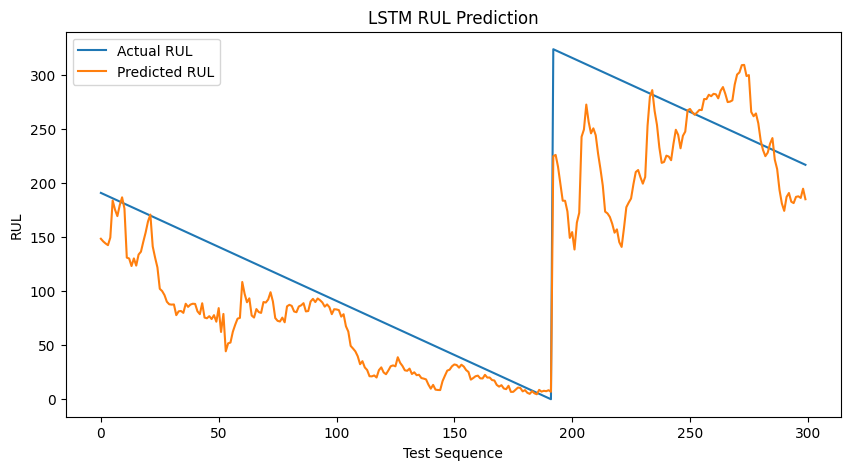

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(y_test_seq[:300], label="Actual RUL")
plt.plot(y_pred[:300], label="Predicted RUL")

plt.xlabel("Test Sequence")
plt.ylabel("RUL")
plt.title("LSTM RUL Prediction")

plt.legend()
plt.show()

# RNN

In [24]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([

    # First RNN layer
    SimpleRNN(
        128,
        return_sequences=True,
        input_shape=(30, 25)
    ),

    # Helps reduce overfitting
    Dropout(0.2),

    # Second RNN layer
    SimpleRNN(64),

    # Helps reduce overfitting
    Dropout(0.2),

    # Fully connected layer
    Dense(32, activation="relu"),

    # Output layer
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [25]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

In [26]:
history = model.fit(

    X_train_seq,
    y_train_seq,

    validation_data=(X_test_seq, y_test_seq),

    epochs=130,

    batch_size=64,

    callbacks=[early_stop]
)

Epoch 1/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 9219.9727 - mae: 74.3408 - val_loss: 7476.3643 - val_mae: 67.7615
Epoch 2/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - loss: 6002.7261 - mae: 59.9019 - val_loss: 5609.5254 - val_mae: 59.5427
Epoch 3/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - loss: 5883.0215 - mae: 60.2967 - val_loss: 4952.1323 - val_mae: 56.8112
Epoch 4/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - loss: 4912.2446 - mae: 54.7991 - val_loss: 4722.7700 - val_mae: 55.4848
Epoch 5/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - loss: 4738.8496 - mae: 53.7542 - val_loss: 4641.9009 - val_mae: 54.9461
Epoch 6/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 4634.2837 - mae: 53.1289 - val_loss: 4553.7490 - val_mae: 54.6926
Epoch 7/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 4553.6289 - mae: 52.5102 - val_loss: 4475.9829 - val_mae: 54.2703
Epoch 8/130
681/681 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 4456.0210 - mae: 51.9080 - val_los

In [27]:
y_pred = model.predict(X_test_seq).flatten()

329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test_seq, y_pred)

mse = mean_squared_error(y_test_seq, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test_seq, y_pred)

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)

MAE  : 41.65955352783203
MSE  : 2960.81591796875
RMSE : 54.41337995354405
R²   : 0.564518928527832
